In [ ]:
import os, zipfile
from pathlib import Path

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
ZIP_PATH = Path(os.environ.get("ZIP_PATH", "/content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/02_Data_Pipeline/Raw/Distrinet-CIC-IDS-2017.zip"))

In [ ]:
extract_to = Path("./extracted_data")

if ZIP_PATH.exists():
    print(f"Đang giải nén {ZIP_PATH} vào {extract_to}...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("Giải nén thành công!")
else:
    print(f"Không tìm thấy tệp tin ZIP tại đường dẫn: {ZIP_PATH}")

Đang giải nén /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/02_Data_Pipeline/Raw/Distrinet-CIC-IDS-2017.zip vào extracted_data...
Giải nén thành công!


In [ ]:
import pandas as pd

# Tìm tất cả các tệp parquet trong thư mục giải nén
parquet_files = list(extract_to.glob("*.parquet"))
print(f"Tìm thấy {len(parquet_files)} tệp parquet:")
for f in parquet_files:
    print(f"- {f.name}")

# Đọc và gộp tất cả các tệp thành một DataFrame duy nhất
if parquet_files:
    df = [pd.read_parquet(file) for file in parquet_files]
    df = pd.concat(df, ignore_index=True)
    print(f"\nGộp thành công! Kích thước DataFrame tổng hợp: {df.shape}")
    display(df.head())
else:
    print("Không tìm thấy tệp .parquet nào trong thư mục.")

Tìm thấy 5 tệp parquet:
- Portscan-DDos-Botnet-Friday.parquet
- Bruteforce-Tuesday.parquet
- Infiltration-Webattacks-Thursday.parquet
- Benign-Monday.parquet
- DoS-Wednesday.parquet

Gộp thành công! Kích thước DataFrame tổng hợp: (1787358, 83)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
0,6,112740690,32,16,6448.0,1152.0,403.0,0.0,201.50,204.724197,...,380.0,343.0,16105402.0,4.988048e+05,16399772.0,15375229.0,-1,-1,112740690,Benign
1,6,112740560,32,16,6448.0,5056.0,403.0,0.0,201.50,204.724197,...,330.0,285.0,16105427.0,4.987937e+05,16399782.0,15375263.0,-1,-1,112740560,Benign
2,0,113757377,545,0,0.0,0.0,0.0,0.0,0.00,0.000000,...,18851792.0,19.0,12210358.0,6.935824e+06,20757030.0,5504997.0,-1,-1,0,Benign
3,17,91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.785320,...,24721964.0,16.0,13197637.0,5.826904e+06,19776792.0,5817470.0,-1,-1,0,Benign
4,17,66966070,6,6,288.0,288.0,48.0,48.0,48.00,0.000000,...,1968172.0,1968172.0,64974432.0,0.000000e+00,64974432.0,64974432.0,-1,-1,0,Benign


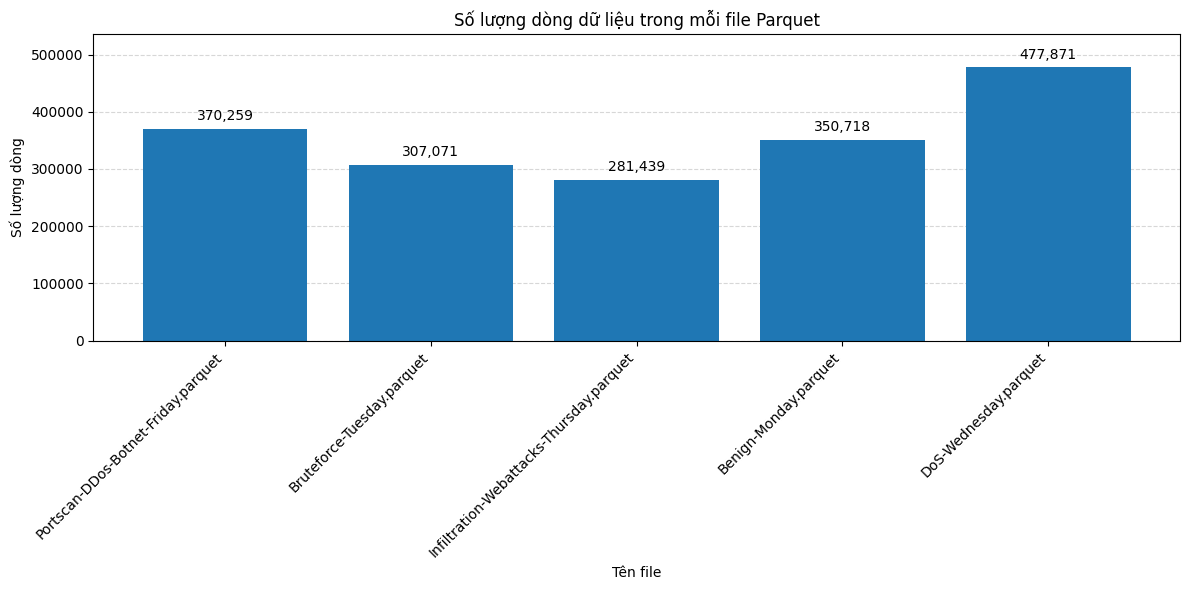

,Tên file,Số lượng dòng
0,Portscan-DDos-Botnet-Friday.parquet,370259
1,Bruteforce-Tuesday.parquet,307071
2,Infiltration-Webattacks-Thursday.parquet,281439
3,Benign-Monday.parquet,350718
4,DoS-Wednesday.parquet,477871


In [ ]:
import matplotlib.pyplot as plt

# Đếm số dòng trong từng file Parquet
row_counts = []

for file in parquet_files:
    df_temp = pd.read_parquet(file)
    row_counts.append({
        "Tên file": file.name,
        "Số lượng dòng": len(df_temp)
    })

stats_df = pd.DataFrame(row_counts)

# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    stats_df["Tên file"],
    stats_df["Số lượng dòng"]
)

# Hiển thị số lượng dòng phía trên mỗi cột
ax.bar_label(
    bars,
    labels=[f"{n:,}" for n in stats_df["Số lượng dòng"]],
    padding=4,
    fontsize=10
)

# Tiêu đề và nhãn trục
ax.set_title("Số lượng dòng dữ liệu trong mỗi file Parquet")
ax.set_xlabel("Tên file")
ax.set_ylabel("Số lượng dòng")

plt.xticks(rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Chừa khoảng trống phía trên để nhãn không bị cắt
ax.margins(y=0.12)

plt.tight_layout()
plt.show()

# Hiển thị bảng thống kê
display(stats_df)


In [ ]:
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Fwd Packets Length Total',
       'Bwd Packets Length Total', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags',
       'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s',
       'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max',
       'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance',
       'FIN Flag 

In [ ]:
label_counts = df['Label'].value_counts()
display(label_counts)

,count
Label,
Benign,1496505
DoS Hulk,158449
DDoS,95144
Attempted-relabel-as-Benign,8966
DoS GoldenEye,7567
Infiltration - Portscan,5485
DoS Slowloris,3998
FTP-Patator,3972
SSH-Patator,2961


Kiểm tra null

In [ ]:
df.isnull().sum()

,0
Protocol,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Fwd Packets Length Total,0
...,...
Idle Min,0
ICMP Code,0
ICMP Type,0
Total TCP Flow Time,0


Kiểm tra trùng lặp

In [ ]:
# Xác định danh sách các cột cần kiểm tra trùng lặp (loại bỏ cột 'Label')
features_cols = [col for col in df.columns if col != 'Label']

# Đếm số lượng dòng trùng lặp
duplicate_count = df.duplicated(subset=features_cols).sum()
print(f"Số lượng dòng trùng lặp (không tính cột 'Label'): {duplicate_count}")

Số lượng dòng trùng lặp (không tính cột 'Label'): 40103


In [ ]:
# Lọc ra các dòng bị trùng lặp dựa trên các cột thuộc tính (features_cols)
duplicates = df[df.duplicated(subset=features_cols, keep=False)]

# Hiển thị 10 dòng trùng lặp đầu tiên kèm theo cột Label
display(duplicates[features_cols + ['Label']].head(10))

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
69,17,17,12,0,468.0,0.0,39.0,39.0,39.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
89,17,15,12,0,540.0,0.0,45.0,45.0,45.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
119,17,48,2,0,124.0,0.0,62.0,62.0,62.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
139,17,20,12,0,2820.0,0.0,235.0,235.0,235.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
345,17,512,1,1,51.0,112.0,51.0,51.0,51.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
411,17,24,13,0,2808.0,0.0,216.0,216.0,216.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
412,17,4,2,0,124.0,0.0,62.0,62.0,62.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
449,17,24,13,0,3055.0,0.0,235.0,235.0,235.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
451,17,3,2,0,124.0,0.0,62.0,62.0,62.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
456,17,23,13,0,3029.0,0.0,233.0,233.0,233.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign


In [ ]:
diff_labels = duplicates.groupby(features_cols).filter(lambda x: x['Label'].nunique() > 1)

# Đếm số dòng bị ảnh hưởng
print(f"Số lượng dòng trùng lặp thuộc tính nhưng KHÁC nhãn Label: {len(diff_labels)}")

# Hiển thị một số ví dụ nếu có
if len(diff_labels) > 0:
    # Sắp xếp theo các cột thuộc tính để dễ dàng quan sát các dòng trùng nhau đứng cạnh nhau
    display(diff_labels.sort_values(by=features_cols)[features_cols + ['Label']].head(10))
else:
    print("Không có dòng nào trùng lặp thuộc tính nhưng khác nhãn Label.")

Số lượng dòng trùng lặp thuộc tính nhưng KHÁC nhãn Label: 1516


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
66072,6,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,1,Portscan
742233,6,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,1,Infiltration - Portscan
779749,6,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,1,Benign
67909,6,2,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,2,Portscan
742240,6,2,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,2,Infiltration - Portscan
65902,6,4,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,4,Portscan
757081,6,4,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,4,Infiltration - Portscan
64964,6,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,5,Portscan
749734,6,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,5,Infiltration - Portscan
64504,6,8,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,8,Portscan


Thực hiện loại bỏ dòng trùng lặp thuộc tính nhưng KHÁC nhãn

In [ ]:
# 1. Xác định các bản ghi bị trùng lặp thuộc tính nhưng có nhãn khác nhau
# Tìm tất cả các nhóm trùng lặp thuộc tính có số lượng nhãn duy nhất lớn hơn 1
conflict_indices = diff_labels.index

In [ ]:
# 2. Loại bỏ các dòng này khỏi DataFrame gốc
df_cleaned = df.drop(index=conflict_indices)

# 3. Cập nhật lại df và hiển thị kích thước mới
print(f"Kích thước ban đầu: {df.shape}")
df = df_cleaned
print(f"Kích thước sau khi loại bỏ xung đột nhãn: {df.shape}")

Kích thước ban đầu: (1787358, 83)
Kích thước sau khi loại bỏ xung đột nhãn: (1785842, 83)
